# BRB modelling：从专家规则到约束训练
复现 Yang 等（2007）第 V 节石墨容器系统的建模与数值监督训练。
[论文 PDF](https://personalpages.manchester.ac.uk/staff/jian-bo.yang/JB%20Yang%20Journal_Papers/SMCA_YLXWW_08_RIMER_Learning.pdf)，DOI 10.1109/TSMCA.2007.897606。
BRB 是规则知识表示，RIMER 是本例使用的推理方法。本 notebook 重点是模型构建和训练。
数据：Table II 的 12 组监督；初始化：Table IV 的 Expert 1（39 条规则）。
训练采用新增 SciPy 约束训练器。论文使用另一求解平台，不能要求局部优化参数完全相同。
源码：[案例配置](../paper_cases/graphite_training.json)、[模型构建](../paper_cases/graphite.py)、[训练器](../../brb/rimer/trainer.py)。

## 1. 运行环境

In [1]:
from pathlib import Path
import sys, platform
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'brb' / 'rimer').is_dir())
sys.path.insert(0, str(root))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.random.seed(2026)
pd.set_option('display.precision', 6)
print('Python:', platform.python_version())
print('Toolkit root located.')


Python: 3.12.14
Toolkit root located.


## 2. 读取论文的 12 个样本
列顺序保留为 X3、X1、X5、X7、X9。X9 为观测置信度。

In [2]:
from examples.paper_cases.graphite import load_graphite_case, build_graphite_model, graphite_inputs
case = load_graphite_case()
training = np.asarray(case['training'], float)
assert training.shape == (12, 5)
display(pd.DataFrame(training, columns=case['column_order'], index=range(1,13)))

,X3,X1,X5,X7,X9
1,0.98,1.0,1.0,1.0,1.0
2,0.98,0.8,0.8,0.8,0.9
3,0.98,0.8,0.2,0.8,0.6
4,0.98,0.4,0.4,0.8,0.3
5,0.98,0.4,0.6,0.8,0.4
6,0.98,1.0,0.0,0.8,0.2
7,0.98,0.0,0.0,0.0,0.0
8,0.98,1.0,1.0,0.2,0.3
9,0.98,0.4,0.6,0.2,0.1
10,0.98,0.6,0.4,0.2,0.2


## 3. 构建层次 BRB
X1→X2；X2、X3→X4；X5、X4→X6；X7、X1→X8；X6、X8→X9。H/M/L 的效用初值为 1/0.5/0。

In [3]:
model = build_graphite_model(training=True)
summary = pd.DataFrame([{'node':n.name,'inputs':', '.join(n.inputs),'rules':len(n.model.config.rule_weights)} for n in model.nodes])
assert summary.rules.sum() == 39
display(summary)

,node,inputs,rules
0,X2,X1,3
1,X8,"X7, X1",9
2,X4,"X2, X3",9
3,X6,"X5, X4",9
4,X9,"X6, X8",9


## 4. 检查专家规则
展示 X9 的九条规则；规则权重 theta、属性权重 delta、后件 beta 是不同参数。

In [4]:
c = model.models['X9'].config
rules = pd.DataFrame(c.rule_beliefs, columns=['beta_H','beta_M','beta_L'])
rules.insert(0, 'antecedents', [str(tuple(c.consequents[j] for j in row)) for row in c.rule_index])
rules['theta'] = c.rule_weights
display(rules)
assert np.allclose(c.rule_beliefs.sum(1), 1)

,antecedents,beta_H,beta_M,beta_L,theta
0,"('H', 'H')",1.0,0.0,0.0,1.0
1,"('H', 'M')",0.2,0.8,0.0,0.6
2,"('H', 'L')",0.1,0.2,0.7,1.0
3,"('M', 'H')",0.2,0.8,0.0,0.6
4,"('M', 'M')",0.0,1.0,0.0,0.6
5,"('M', 'L')",0.0,0.1,0.9,1.0
6,"('L', 'H')",0.1,0.2,0.7,1.0
7,"('L', 'M')",0.0,0.1,0.9,1.0
8,"('L', 'L')",0.0,0.0,1.0,1.0


## 5. 旧接口仍可用于完整单层 BRB
用 X1→X2 身份规则做兼容检查。零信念在旧 softmax 接口中用 10⁻¹⁴ 近似；层次训练继续使用新增论文模块。

In [5]:
import torch
from brb.config import BRBConfig, AttributeConfig
from brb.model import BRBModel
old = BRBModel(BRBConfig('X2',[AttributeConfig('X1','numeric',[0,.5,1])],[0,.5,1]))
with torch.no_grad():
    old.belief_logits.copy_(torch.log(torch.eye(3,dtype=torch.float64)+1e-14))
    old_values, _ = old(torch.tensor([[0],[.5],[1]],dtype=torch.float64))
np.testing.assert_allclose(old_values.detach().numpy(), [0,.5,1], atol=1e-10)
print('Original BRBModel compatibility:', old_values.detach().numpy())

Original BRBModel compatibility: [1.5e-14 5.0e-01 1.0e+00]


## 6. 初始模型预测
监督误差是论文数值输出目标的均方误差。

In [6]:
inputs = graphite_inputs(training[:,:4])
initial = model.infer(inputs).expected_value(model.models['X9'].config.utilities)
initial_mse = np.mean((initial-training[:,4])**2)
print('Initial MSE:', initial_mse)

Initial MSE: 0.03171046834080781


## 7. 约束训练
联合学习 beta、theta、delta 和有序效用；beta 行和为 1，权重在 [0,1]。保留真实求解状态。通常需要一至几分钟。

In [7]:
from brb.rimer import RIMERTrainer, RIMERSupervision
fit = RIMERTrainer(maxiter=200, ftol=1e-9).fit(model, inputs,
    RIMERSupervision(numeric=training[:,4]),
    trainable={'beta':True,'theta':True,'delta':True,'utilities':True})
display(pd.DataFrame([{k:getattr(fit,k) for k in ['objective_before','objective_after','success','status','iterations','constraint_violation']}]))
assert fit.success, fit.status
assert fit.constraint_violation < 1e-7

,objective_before,objective_after,success,status,iterations,constraint_violation
0,0.03171,7.156745e-08,True,Optimization terminated successfully,98,2.220446e-16


## 8. 观测和计算值对照
`paper_reference` 指 Table II 的观测目标，不冒充论文的求解器输出。

In [8]:
computed = model.infer(inputs).expected_value(model.models['X9'].config.utilities)
comparison = pd.DataFrame({'paper_reference':training[:,4], 'initial':initial,'computed':computed,'absolute_error':abs(computed-training[:,4])},index=range(1,13))
display(comparison)
print('Learned utilities H/M/L:', model.models['X9'].config.utilities)

,paper_reference,initial,computed,absolute_error
1,1.0,1.000000,0.999155,0.000845
2,0.9,0.914109,0.900014,0.000014
3,0.6,0.171327,0.599943,0.000057
4,0.3,0.424970,0.300019,0.000019
5,0.4,0.520009,0.399940,0.000060
6,0.2,0.162627,0.200009,0.000009
7,0.0,0.000000,0.000360,0.000360
8,0.3,0.666844,0.300005,0.000005
9,0.1,0.091071,0.100081,0.000081
10,0.2,0.103612,0.200007,0.000007


Learned utilities H/M/L: [1.        0.1531068 0.       ]


## 9. 训练前后图

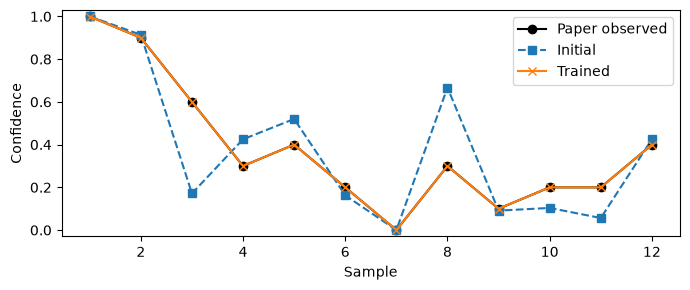

In [9]:
fig, ax = plt.subplots(figsize=(7,3))
ax.plot(range(1,13), training[:,4], 'ko-', label='Paper observed')
ax.plot(range(1,13), initial, 's--', label='Initial')
ax.plot(range(1,13), computed, 'x-', label='Trained')
ax.set(xlabel='Sample', ylabel='Confidence', ylim=(-.03,1.03))
ax.legend(); fig.tight_layout(); plt.show()

## 10. 验收与解释
本例验证约束训练可行及样本拟合改善。只有 12 个训练样本，不能据此证明新输入上的泛化性能；未激活的规则缺乏数据支持。

In [10]:
assert fit.objective_after < initial_mse
assert fit.objective_after < 1e-6
for node in model.models.values():
    np.testing.assert_allclose(node.config.rule_beliefs.sum(1),1,atol=1e-7)
print('Verified: 39-rule model, 12 observations, constrained local training.')

Verified: 39-rule model, 12 observations, constrained local training.
